# NLP with Disaster Tweets - EDA & Baseline

**Автор:** Назаров Владимир

**GitHub:** [github.com/AmbiValent17](https://github.com/AmbiValent17)

**Kaggle:** [NLP with Disaster Tweets](https://www.kaggle.com/competitions/nlp-getting-started/overview)

---

## О проекте

Бинарная классификация твитов: является ли сообщение описанием реального
бедствия (`target=1`) или нет (`target=0`).

Цель - пройти
полный цикл работы с NLP-задачей: EDA, предобработка текста, baseline-модель,
оценка и выводы

## Данные

- **Источник:** Kaggle Competition "NLP with Disaster Tweets" (Getting Started).
- **train.csv:** ~7 613 твитов с колонками `id`, `keyword`, `location`, `text`, `target`.
- **test.csv:** ~3 263 твита без `target`.
- **Метрика:** F1-score.

## План ноутбука

1. Загрузка данных.
2. Разведочный анализ (EDA).
3. Очистка текста и удаление дубликатов.
4. Baseline: TF-IDF + Logistic Regression.
5. Оценка на кросс-валидации, confusion matrix.
6. Выводы и сохранение предсказаний для сравнения с трансформером.

## Стек

- Python 3.10+
- pandas, numpy
- scikit-learn
- matplotlib, seaborn

## Загрузка данных

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
DATA_DIR = Path('data')

In [26]:
train = pd.read_csv(Path(DATA_DIR) / "train.csv")
test = pd.read_csv(Path(DATA_DIR) / "test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

Train shape: (7613, 5)
Test shape: (3263, 4)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


## Разведочный анализ (EDA)

In [27]:
print("\nInfo:")
train.info()


Info:
<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7613 non-null   int64
 1   keyword   7552 non-null   str  
 2   location  5080 non-null   str  
 3   text      7613 non-null   str  
 4   target    7613 non-null   int64
dtypes: int64(2), str(3)
memory usage: 1.2 MB


### Пропуски и дубликаты

In [28]:
print("\nПропуски (train):")
print(train.isnull().sum())

print("\nПропуски (test):")
print(test.isnull().sum())

print("\nДубликаты по text в train:", train['text'].duplicated().sum())


Пропуски (train):
id             0
keyword       61
location    2533
text           0
target         0
dtype: int64

Пропуски (test):
id             0
keyword       26
location    1105
text           0
dtype: int64

Дубликаты по text в train: 110


В ``keyword`` мало пропусков (61), поэтому заполним отдельным значением *none*

In [29]:
train['keyword'] = train['keyword'].fillna('none')
test['keyword'] = test['keyword'].fillna('none')

Колонка ``location``:
- Содержит около 33% пропусков + 
- Содержит много мусорных значений (свободный текст, опетачки). 

В связи с чем в baseline решено полностью убрать её из фичей

In [30]:
train = train.drop(columns=['location'])
test = test.drop(columns=['location'])

Проверим на наличие конфликтующих по ``target`` дубликатов по колонке ``text``

In [31]:
dup_mask = train['text'].duplicated(keep=False)
dups = train[dup_mask].sort_values('text').reset_index(drop=True)

print(f"Всего строк в train: {len(train)}")
print(f"Строк с дублирующимся текстом: {len(dups)}")
print(f"Уникальных текстов среди них: {dups['text'].nunique()}")

Всего строк в train: 7613
Строк с дублирующимся текстом: 179
Уникальных текстов среди них: 69


In [32]:
label_counts = dups.groupby('text')['target'].nunique()

conflict_texts = label_counts[label_counts > 1].index
same_label_texts = label_counts[label_counts == 1].index

print(f"Уникальных текстов с конфликтом меток: {len(conflict_texts)}")
print(f"Уникальных текстов с одинаковой меткой: {len(same_label_texts)}")

conflict_rows = dups[dups['text'].isin(conflict_texts)]
same_label_rows = dups[dups['text'].isin(same_label_texts)]

print(f"\nСтрок в конфликтующих группах: {len(conflict_rows)}")
print(f"Строк в группах с одинаковой меткой: {len(same_label_rows)}")
conflict_rows

Уникальных текстов с конфликтом меток: 18
Уникальных текстов с одинаковой меткой: 51

Строк в конфликтующих группах: 55
Строк в группах с одинаковой меткой: 124


,id,keyword,text,target
0,6094,hellfire,#Allah describes piling up #wealth thinking it...,0
1,6105,hellfire,#Allah describes piling up #wealth thinking it...,0
2,6123,hellfire,#Allah describes piling up #wealth thinking it...,1
19,5996,hazardous,#foodscare #offers2go #NestleIndia slips into ...,1
20,6023,hazardous,#foodscare #offers2go #NestleIndia slips into ...,1
21,6031,hazardous,#foodscare #offers2go #NestleIndia slips into ...,0
28,4068,displaced,.POTUS #StrategicPatience is a strategy for #G...,1
29,4072,displaced,.POTUS #StrategicPatience is a strategy for #G...,1
30,4076,displaced,.POTUS #StrategicPatience is a strategy for #G...,0
31,4077,displaced,.POTUS #StrategicPatience is a strategy for #G...,1


- Удалим все строки, тексты в которых совпадают, но есть конфликт по метке
- Если тексты совпадают в нескольких строках, но метки одинаковые, то оставляем один экземпляр

In [33]:
train_clean = train[~train['text'].isin(conflict_texts)].copy() # удаляем конфликтные дубликаты
train_clean = train_clean.drop_duplicates(subset='text', keep='first').reset_index(drop=True) # удаляем неконфликтные дубликаты

print(f"\nБыло: {len(train)}")
print(f"Стало: {len(train_clean)}")
print(f"Удалено: {len(train) - len(train_clean)}")
print(f"\nДубликатов осталось: {train_clean['text'].duplicated().sum()}")
print(f"Конфликтов осталось: {train_clean.groupby('text')['target'].nunique().gt(1).sum()}")


Было: 7613
Стало: 7485
Удалено: 128

Дубликатов осталось: 0
Конфликтов осталось: 0


### Сбалансированность классов

target
0    4297
1    3188
Name: count, dtype: int64


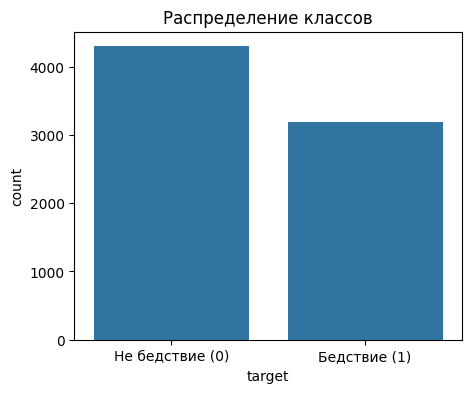

In [34]:
print(train_clean['target'].value_counts())

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='target', data=train_clean, ax=ax)
ax.set_title('Распределение классов')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Не бедствие (0)', 'Бедствие (1)'])

plt.show()

Умеренный дисбаланс. Далее сравню результаты обучения с балансировкой и без.

## Топ-слова

In [35]:
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words('english'))

def tokenize(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'&\w+;', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    return [w for w in text.split() if w not in STOPWORDS and len(w) > 2]

def top_words(texts, n=20):
    words = []
    for t in texts:
        words.extend(tokenize(t))
    return Counter(words).most_common(n)

top_pos = top_words(train_clean[train_clean['target'] == 1]['text'], 20)
top_neg = top_words(train_clean[train_clean['target'] == 0]['text'], 20)

In [36]:
print("Топ-20 слов при target=1")
for w, c in top_pos:
    print(f"{w} {c}")

Топ-20 слов при target=1
fire 177
news 144
via 119
disaster 116
california 114
police 107
suicide 106
people 101
killed 95
hiroshima 93
like 91
storm 89
crash 85
fires 84
families 79
emergency 77
nuclear 73
two 71
train 71
attack 71


In [37]:
print("\nТоп-20 слов при target=0")
for w, c in top_neg:
    print(f"{w} {c}")


Топ-20 слов при target=0
like 252
new 171
get 163
one 133
body 116
would 99
via 98
video 95
love 91
people 91
day 86
know 86
got 85
back 85
time 84
full 83
see 82
emergency 80
going 76
still 72


Видим наличие сигнала в текстах - при target=1 часто встречаются соответствующие слова (killed, crash, fire, ...), при target=0 большинство слов не относится бедствиям и катастрофам

### Длина текстов

In [38]:
train_clean['char_len'] = train_clean['text'].str.len()
train_clean['word_len'] = train_clean['text'].str.split().str.len()

print("Символы")
print(train_clean.groupby('target')['char_len'].describe().round(1))

print("\nСлова")
print(train_clean.groupby('target')['word_len'].describe().round(1))

Символы
         count   mean   std   min   25%    50%    75%    max
target                                                      
0       4297.0   95.6  35.9   7.0  68.0  101.0  130.0  157.0
1       3188.0  108.0  29.3  14.0  88.0  114.0  135.0  151.0

Слова
         count  mean  std  min   25%   50%   75%   max
target                                                
0       4297.0  14.7  6.2  1.0  10.0  15.0  19.0  31.0
1       3188.0  15.1  5.1  2.0  11.0  15.0  19.0  30.0


- В словах классы не различаются - длина как признак бесполезна.
- В символах target=1 длиннее: твиты о бедствиях используют более
  длинные слова (earthquake, emergency vs like, love).

Соответственно, буду ставить `max_length=64` для токенизатора с запасом. `word_len`
в признаки не добавляю - сигнала нет.

### Выводы по EDA

1. **Данные:** 7613 строк в train, 3263 в test. После очистки дубликатов — X строк.
2. **Классы:** 57% / 43% - умеренный дисбаланс, для F1 не критичен.
3. **Пропуски:** `keyword` заполнен `'none'`, `location` (33% пропусков) не используется.
4. **Дубликаты:** конфликты меток удалены, дубликаты по тексту убраны.
5. **Текст:** классы разделяются лексически - disaster-лексика vs бытовая.
6. **Длина:** max 31 слово -> `max_length=64` для токенизатора.

## Baseline: TF-IDF + LogisticRegression

Простой baseline для сравнения с трансформером.
Пайплайн: очистка текста -> TF-IDF -> LogReg -> 5-fold CV по F1.

In [39]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'&\w+;', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_clean['text_clean'] = train_clean['text'].apply(clean_text)

print("До:")
print(train_clean['text'].iloc[2])
print("\nПосле:")
print(train_clean['text_clean'].iloc[2])

До:
All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected

После:
all residents asked to shelter in place are being notified by officers no other evacuation or shelter in place orders are expected


In [ ]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    stop_words=list(STOPWORDS),
    sublinear_tf=True,
)

X = tfidf.fit_transform(train_clean['text_clean'])
y = train_clean['target']

print("Размер матрицы:", X.shape)
print("Пример признаков:", tfidf.get_feature_names_out()[:10])

Размер матрицы: (7485, 10535)
Пример признаков: ['aa' 'aba' 'aba woman' 'abandon' 'abandoned' 'abandoned aircraft'
 'abbott' 'abbswinston' 'abbswinston zionist' 'abc']


In [48]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
scores = cross_val_score(clf, X, y, cv=skf, scoring='f1')

print(f"F1 по фолдам: {scores.round(3)}")
print(f"F1: {scores.mean():.4f} +- {scores.std():.4f}")

F1 по фолдам: [0.727 0.731 0.763 0.737 0.743]
F1: 0.7404 +- 0.0125


### Попробуем с балансировкой классов

In [50]:
clf_bal  = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
scores_bal = cross_val_score(clf_bal, X, y, cv=skf, scoring='f1')

print(f"Без балансировки: {scores.mean():.4f} +- {scores.std():.4f}")
print(f"С балансировкой:  {scores_bal.mean():.4f} +- {scores_bal.std():.4f}")
print(f"Разница:          {scores_bal.mean() - scores.mean():+.4f}")

Без балансировки: 0.7404 +- 0.0125
С балансировкой:  0.7604 +- 0.0131
Разница:          +0.0200


Балансировка классов даёт прирост F1: 0.740 -> 0.760

              precision    recall  f1-score   support

 Не бедствие       0.80      0.86      0.83       859
    Бедствие       0.79      0.71      0.75       638

    accuracy                           0.80      1497
   macro avg       0.80      0.79      0.79      1497
weighted avg       0.80      0.80      0.80      1497



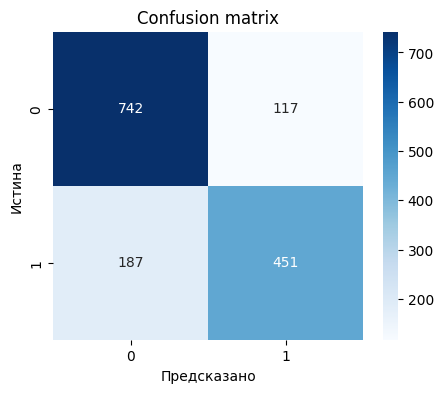

In [53]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

best_clf = LogisticRegression(
    max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
)
best_clf.fit(X_train, y_train)
y_pred = best_clf.predict(X_val)

print(classification_report(y_val, y_pred, target_names=['Не бедствие', 'Бедствие']))

cm = confusion_matrix(y_val, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0', '1'], yticklabels=['0', '1'], ax=ax)
ax.set_xlabel('Предсказано')
ax.set_ylabel('Истина')
ax.set_title('Confusion matrix')
plt.show()

Модель склонна ошибаться именно на примерах с меткой 1 (предсказывать 0)

### Подбор порога

In [56]:
probs = best_clf.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.3, 0.7, 0.02)
results = []

for threshold in thresholds:
    y_pred_t = (probs > threshold).astype(int)
    results.append({
        'threshold': round(threshold, 2),
        'f1': f1_score(y_val, y_pred_t),
        'precision': precision_score(y_val, y_pred_t),
        'recall': recall_score(y_val, y_pred_t),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

best_t = results_df.loc[results_df['f1'].idxmax(), 'threshold']
print(f"\nЛучший threshold по F1: {best_t}")

 threshold       f1  precision   recall
      0.30 0.670435   0.524315 0.929467
      0.32 0.686585   0.548176 0.918495
      0.34 0.692683   0.566866 0.890282
      0.36 0.703939   0.591880 0.868339
      0.38 0.713528   0.618391 0.843260
      0.40 0.730314   0.657465 0.821317
      0.42 0.736383   0.686062 0.794671
      0.44 0.742515   0.710602 0.777429
      0.46 0.747459   0.745710 0.749216
      0.48 0.748594   0.767710 0.730408
      0.50 0.747927   0.794014 0.706897
      0.52 0.737201   0.808989 0.677116
      0.54 0.731239   0.824803 0.656740
      0.56 0.715064   0.849138 0.617555
      0.58 0.701203   0.855530 0.594044
      0.60 0.691943   0.875300 0.572100
      0.62 0.666667   0.877238 0.537618
      0.64 0.648594   0.902235 0.506270
      0.66 0.627049   0.905325 0.479624
      0.68 0.595970   0.921311 0.440439

Лучший threshold по F1: 0.48


Перебор порогов 0.30-0.70 показал, что максимум F1 достигается при threshold 0.48 - 
практически совпадает с дефолтным 0.5. Дополнительная настройка порога не требуется.